# FGM Attitudinal Incidence, Kenya — v3 methodology

Version 3 is the survey-weighted, covariate-adjusted spatial attitude pipeline.
It keeps the design-based estimates as the population benchmark and fits the
selected attitude predictors together with a BYM2 regional effect. Full posterior
respondent probabilities are aggregated with DHS weights to produce adjusted
national and regional estimates.

Major corrections relative to v2:

1. Age is restored from the prevalence respondent file and screened for the
   attitude outcome.
2. Feature selection is attitude-specific; prevalence predictors are not reused
   automatically.
3. Normalized DHS weights enter the INLA pseudo-likelihood and the aggregation.
4. Covariates and the BYM2 spatial effect are fitted in one model.
5. The outcome-derived `community_support_rate` is removed to prevent leakage.
6. The divergent `multilevel_EM` option and the experimental cluster map are not
   used. The final map is regional and covariate-adjusted.
7. Direct, spatial-only and covariate-adjusted results are compared explicitly.

Run the cells in order.

## 0. Configuration

In [1]:
country_name <- "Kenya"
country_iso3 <- "KEN"

# Works whether the kernel starts in the project root or in 01_Notebooks.
project_root <- if (dir.exists("../02_Data")) ".." else "."

combined_data_dir <- file.path(project_root, "02_Data", "processed", country_iso3, "combined")
prevalence_data_dir <- file.path(project_root, "02_Data", "processed", country_iso3, "2022")
output_dir <- file.path(project_root, "03_Outputs", country_iso3, "Attitude_v3")

admin_level <- "admin1"
shapefile_path <- file.path(
  project_root, "02_Data", "raw", "2022", "Survey", "boundaries",
  "Kenya Boundaries", "shps", "sdr_subnational_boundaries.shp"
)
region_var_shapefile <- "DHSREGEN"
standardize_region <- function(x) {
  x |> as.character() |> toupper() |>
    stringr::str_replace_all("[^A-Z ]", " ") |> stringr::str_squish()
}

posterior_draws <- 500L
vif_threshold <- 2
missingness_threshold <- 0.30
set.seed(20260918)

dir.create(output_dir, recursive = TRUE, showWarnings = FALSE)

cat("Configured for:", country_name, paste0("(", country_iso3, ")"), "\n")
cat("Outputs:", normalizePath(output_dir, mustWork = FALSE), "\n")

Configured for: Kenya (KEN) 


Outputs: /Users/jkakai/Desktop/Main/Melaningod/UNFPA/Root/Working Folder/FGM_Risk_Attitude_Prevelance/03_Outputs/KEN/Attitude_v3 


## 1. Setup

In [2]:
required_packages <- c(
  "tidyverse", "survey", "sf", "spdep", "INLA", "randomForest", "car"
)

missing_packages <- required_packages[
  !vapply(required_packages, requireNamespace, logical(1), quietly = TRUE)
]
if (length(missing_packages) > 0L) {
  stop("Install the missing packages before continuing: ",
       paste(missing_packages, collapse = ", "))
}

suppressPackageStartupMessages({
  library(tidyverse)
  library(survey)
  library(sf)
  library(spdep)
  library(randomForest)
  library(car)
})

options(survey.lonely.psu = "adjust")
options(repr.matrix.max.cols = Inf)
options(repr.plot.width = 11, repr.plot.height = 8)
theme_set(ggplot2::theme_minimal(base_size = 12))

## 2. Load and enrich the attitude data

The prepared attitude file contains only respondents with a known answer to
whether FGM should continue or stop. Age was omitted from that file in the
upstream preparation, so it is restored by respondent ID from the corrected
prevalence respondent file. This is a one-to-one join and is checked below.

In [3]:
attitude_path <- file.path(combined_data_dir, paste0(country_iso3, "_attitude.rds"))
women_path <- file.path(prevalence_data_dir, "person_level.rds")

if (!file.exists(attitude_path)) stop("Missing: ", attitude_path)
if (!file.exists(women_path)) stop("Missing: ", women_path)

attitude_raw <- readRDS(attitude_path)
women_lookup <- readRDS(women_path) |>
  dplyr::select(resp_id, age, birth_year) |>
  dplyr::distinct(resp_id, .keep_all = TRUE)

if (anyDuplicated(attitude_raw$id)) stop("Duplicate respondent IDs in attitude data")
if (anyDuplicated(women_lookup$resp_id)) stop("Duplicate respondent IDs in age lookup")

attitude_all <- attitude_raw |>
  dplyr::left_join(women_lookup, by = c("id" = "resp_id")) |>
  dplyr::mutate(
    region = standardize_region(region),
    age = as.numeric(age),
    birth_year = as.numeric(birth_year)
  )

if (anyNA(attitude_all$age)) {
  stop("Age join failed for ", sum(is.na(attitude_all$age)), " respondents")
}

cat("Attitude respondents:", nrow(attitude_all), "\n")
cat("Known attitude outcomes:", sum(!is.na(attitude_all$supports_continuation)), "\n")
cat("Supports continuation:", sum(attitude_all$supports_continuation == 1), "\n")
cat("Supports stopping:", sum(attitude_all$supports_continuation == 0), "\n")
cat("Age range:", paste(range(attitude_all$age), collapse = " to "), "\n")
cat("Regions:", dplyr::n_distinct(attitude_all$region), "\n")

dplyr::glimpse(attitude_all)

Attitude respondents: 15890 


Known attitude outcomes: 15890 


Supports continuation: 1606 


Supports stopping: 14284 


Age range: 15 to 49 


Regions: 47 


Rows: 15,890
Columns: 21
$ id                    <chr> "2022-1-4-2", "2022-1-10-1", "2022-1-13-2", "202…
$ survey_type           <chr> "DHS", "DHS", "DHS", "DHS", "DHS", "DHS", "DHS",…
$ survey_year           <int> 2022, 2022, 2022, 2022, 2022, 2022, 2022, 2022, …
$ country               <chr> "KEN", "KEN", "KEN", "KEN", "KEN", "KEN", "KEN",…
$ region                <chr> "MOMBASA", "MOMBASA", "MOMBASA", "MOMBASA", "MOM…
$ cluster               <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, …
$ urban_rural           <chr> "urban", "urban", "urban", "urban", "urban", "ur…
$ weight                <dbl> 1.296049, 1.296049, 1.296049, 1.296049, 1.296049…
$ psu                   <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, …
$ strata                <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, …
$ lat                   <dbl> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, …
$ lon                   <dbl> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, …
$ missing_gps  

## 3. Attitude-specific predictor screening

The candidate variables are screened against `supports_continuation`, not
against FGM prevalence. Random-forest permutation importance is used only for
ranking; it is not interpreted causally. Predictors are removed only for severe
missingness or problematic collinearity. Own FGM status and age are retained a
priori because they are substantively necessary attitude determinants.

In [4]:
candidate_predictors <- c(
  "own_status", "age", "education", "wealth", "religion",
  "ethnicity", "urban_rural", "region"
)

missingness <- attitude_all |>
  dplyr::summarise(
    dplyr::across(dplyr::all_of(candidate_predictors), ~mean(is.na(.)))
  ) |>
  tidyr::pivot_longer(
    dplyr::everything(), names_to = "variable", values_to = "proportion_missing"
  ) |>
  dplyr::mutate(percent_missing = 100 * proportion_missing)

print(missingness)

eligible_predictors <- missingness |>
  dplyr::filter(proportion_missing < missingness_threshold) |>
  dplyr::pull(variable)

rf_data <- attitude_all |>
  dplyr::select(supports_continuation, dplyr::all_of(eligible_predictors)) |>
  tidyr::drop_na() |>
  dplyr::mutate(
    supports_continuation = factor(supports_continuation),
    own_status = factor(own_status, levels = c(0, 1), labels = c("Not cut", "Cut")),
    dplyr::across(dplyr::where(is.character), as.factor)
  )

rf_model <- randomForest::randomForest(
  supports_continuation ~ ., data = rf_data,
  ntree = 500, importance = TRUE
)

rf_importance <- randomForest::importance(rf_model)
importance_column <- if ("MeanDecreaseAccuracy" %in% colnames(rf_importance)) {
  "MeanDecreaseAccuracy"
} else {
  "MeanDecreaseGini"
}

importance_ranked <- rf_importance |>
  as.data.frame() |>
  tibble::rownames_to_column("variable") |>
  dplyr::arrange(dplyr::desc(.data[[importance_column]]))

cat("Rows in feature screen:", nrow(rf_data), "\n")
cat("Importance measure:", importance_column, "\n")
print(importance_ranked)

readr::write_csv(
  importance_ranked,
  file.path(output_dir, paste0(country_iso3, "_attitude_feature_importance_v3.csv"))
)

# A tibble: 8 × 3
  variable    proportion_missing percent_missing
  <chr>                    <dbl>           <dbl>
1 own_status                   0               0
2 age                          0               0
3 education                    0               0
4 wealth                       0               0
5 religion                     0               0
6 ethnicity                    0               0
7 urban_rural                  0               0
8 region                       0               0


Rows in feature screen: 15890 


Importance measure: MeanDecreaseAccuracy 


     variable        0         1 MeanDecreaseAccuracy MeanDecreaseGini
1      region 55.71963 13.615707             54.75286        633.26334
2  own_status 39.21409 34.984600             54.60031        237.69214
3   ethnicity 33.13473 20.892311             35.66923        547.67290
4   education 10.73326 37.628326             32.50905        160.55742
5      wealth 16.03766 15.413364             24.28849         91.33346
6    religion 14.73600 19.746367             22.46552        310.32111
7         age 21.98654 -1.308489             20.55373        137.72136
8 urban_rural 14.47158 -3.549343             14.40553         22.16974


## 4. Collinearity and final predictor selection

In [5]:
vif_formula <- stats::reformulate(
  eligible_predictors, response = "supports_continuation"
)
vif_check_model <- stats::glm(vif_formula, data = rf_data, family = stats::binomial())
vif_raw <- car::vif(vif_check_model)
vif_adjusted <- if (is.matrix(vif_raw)) {
  vif_raw[, "GVIF^(1/(2*Df))"]
} else {
  sqrt(vif_raw)
}

vif_table <- tibble::tibble(
  variable = names(vif_adjusted), adjusted_vif = as.numeric(vif_adjusted)
) |>
  dplyr::arrange(dplyr::desc(adjusted_vif))

print(vif_table)

vif_flagged <- vif_table |>
  dplyr::filter(adjusted_vif > vif_threshold) |>
  dplyr::pull(variable)

ranked_names <- importance_ranked$variable
selected_predictors <- setdiff(ranked_names, vif_flagged)

# These two variables were specified a priori and are not dropped mechanically.
selected_predictors <- unique(c("own_status", "age", selected_predictors))
selected_predictors <- selected_predictors[selected_predictors %in% eligible_predictors]

cat("Final attitude predictor list:\n")
print(selected_predictors)
cat("Region will be represented by the BYM2 effect rather than a fixed effect.\n")

saveRDS(
  selected_predictors,
  file.path(output_dir, paste0(country_iso3, "_attitude_selected_predictors_v3.rds"))
)
readr::write_csv(
  tibble::tibble(variable = selected_predictors),
  file.path(output_dir, paste0(country_iso3, "_attitude_selected_predictors_v3.csv"))
)
readr::write_csv(
  vif_table,
  file.path(output_dir, paste0(country_iso3, "_attitude_vif_v3.csv"))
)

# A tibble: 8 × 2
  variable    adjusted_vif
  <chr>              <dbl>
1 ethnicity           1.74
2 urban_rural         1.52
3 own_status          1.50
4 age                 1.17
5 education           1.16
6 wealth              1.15
7 religion            1.14
8 region              1.11


Final attitude predictor list:


[1] "own_status"  "age"         "region"      "ethnicity"   "education"  
[6] "wealth"      "religion"    "urban_rural"


Region will be represented by the BYM2 effect rather than a fixed effect.


## 5. Mixed-variable association matrix

This descriptive matrix uses absolute Spearman correlation for two numeric
variables, bias-corrected Cramér's V for two categorical variables, and the
correlation ratio for numeric–categorical pairs. Values measure association
strength from 0 to 1; they do not show causal effects or direction.

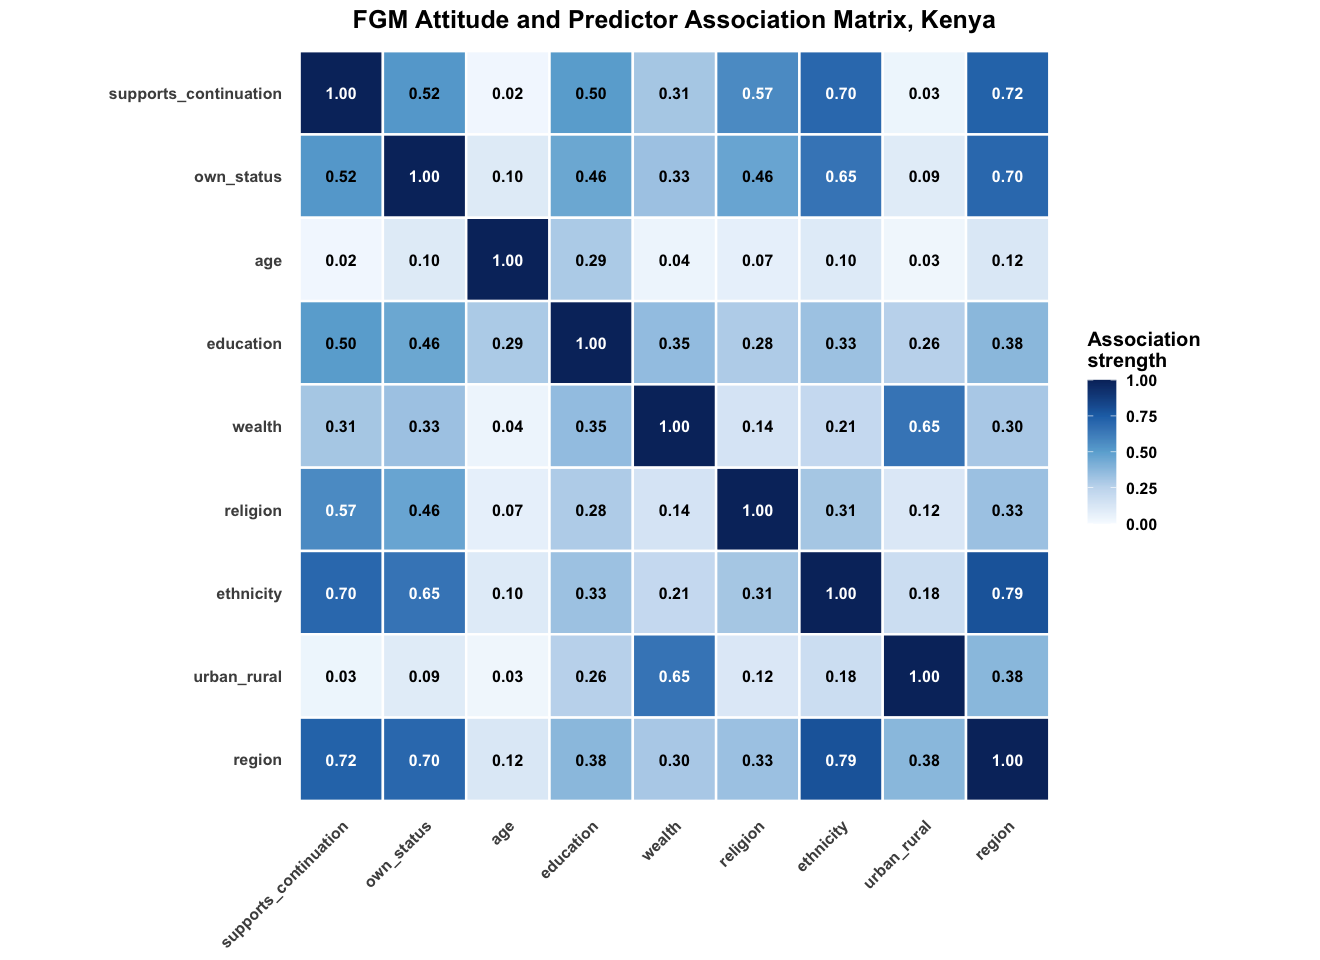

In [6]:
cramers_v_corrected <- function(x, y) {
  keep <- stats::complete.cases(x, y)
  x <- droplevels(as.factor(x[keep]))
  y <- droplevels(as.factor(y[keep]))
  if (length(x) == 0L || nlevels(x) < 2L || nlevels(y) < 2L) return(NA_real_)
  tab <- table(x, y)
  chi2 <- suppressWarnings(as.numeric(stats::chisq.test(tab, correct = FALSE)$statistic))
  n <- sum(tab); r <- nrow(tab); k <- ncol(tab)
  phi2 <- chi2 / n
  phi2c <- max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
  rc <- r - ((r - 1)^2) / (n - 1)
  kc <- k - ((k - 1)^2) / (n - 1)
  den <- min(rc - 1, kc - 1)
  if (!is.finite(den) || den <= 0) return(NA_real_)
  sqrt(phi2c / den)
}

correlation_ratio <- function(x_numeric, y_category) {
  keep <- stats::complete.cases(x_numeric, y_category)
  x <- as.numeric(x_numeric[keep])
  y <- droplevels(as.factor(y_category[keep]))
  if (length(unique(x)) < 2L || nlevels(y) < 2L) return(NA_real_)
  grand_mean <- mean(x)
  groups <- split(x, y)
  between <- sum(vapply(groups, function(z) length(z) * (mean(z) - grand_mean)^2,
                        numeric(1)))
  total <- sum((x - grand_mean)^2)
  if (!is.finite(total) || total <= 0) return(NA_real_)
  sqrt(max(0, min(1, between / total)))
}

mixed_association <- function(x, y) {
  xn <- is.numeric(x); yn <- is.numeric(y)
  if (xn && yn) {
    keep <- stats::complete.cases(x, y)
    if (sum(keep) < 3L || length(unique(x[keep])) < 2L ||
        length(unique(y[keep])) < 2L) return(NA_real_)
    return(abs(stats::cor(x[keep], y[keep], method = "spearman")))
  }
  if (!xn && !yn) return(cramers_v_corrected(x, y))
  if (xn) correlation_ratio(x, y) else correlation_ratio(y, x)
}

association_data <- attitude_all |>
  dplyr::select(supports_continuation, dplyr::all_of(eligible_predictors)) |>
  dplyr::mutate(
    supports_continuation = factor(
      supports_continuation, levels = c(0, 1), labels = c("Stop", "Continue")
    ),
    own_status = factor(own_status, levels = c(0, 1), labels = c("Not cut", "Cut")),
    dplyr::across(dplyr::where(is.character), as.factor)
  )

association_names <- names(association_data)
association_matrix <- matrix(
  NA_real_, length(association_names), length(association_names),
  dimnames = list(association_names, association_names)
)
for (i in seq_along(association_names)) {
  for (j in seq_along(association_names)) {
    association_matrix[i, j] <- if (i == j) 1 else mixed_association(
      association_data[[i]], association_data[[j]]
    )
  }
}

association_long <- as.data.frame(association_matrix) |>
  tibble::rownames_to_column("variable_y") |>
  tidyr::pivot_longer(-variable_y, names_to = "variable_x", values_to = "association") |>
  dplyr::mutate(
    variable_x = factor(variable_x, levels = association_names),
    variable_y = factor(variable_y, levels = rev(association_names)),
    value_label = dplyr::if_else(is.na(association), "NA", sprintf("%.2f", association))
  )

association_plot <- ggplot2::ggplot(
  association_long,
  ggplot2::aes(variable_x, variable_y, fill = association)
) +
  ggplot2::geom_tile(color = "white", linewidth = 0.7) +
  ggplot2::geom_text(
    ggplot2::aes(label = value_label, color = association >= 0.55),
    fontface = "bold", size = 3.4
  ) +
  ggplot2::scale_fill_gradientn(
    colors = c("#F7FBFF", "#C6DBEF", "#6BAED6", "#2171B5", "#08306B"),
    limits = c(0, 1), name = "Association\nstrength", na.value = "grey85"
  ) +
  ggplot2::scale_color_manual(values = c(`FALSE` = "black", `TRUE` = "white"), guide = "none") +
  ggplot2::coord_fixed() +
  ggplot2::labs(
    title = paste("FGM Attitude and Predictor Association Matrix,", country_name),
    x = NULL, y = NULL
  ) +
  ggplot2::theme_minimal(base_size = 12) +
  ggplot2::theme(
    text = ggplot2::element_text(face = "bold"),
    plot.title = ggplot2::element_text(hjust = 0.5, size = 15),
    axis.text.x = ggplot2::element_text(angle = 45, hjust = 1),
    panel.grid = ggplot2::element_blank()
  )

print(association_plot)
ggplot2::ggsave(
  file.path(output_dir, paste0(country_iso3, "_attitude_association_matrix_v3.png")),
  association_plot, width = 10, height = 8, dpi = 300, bg = "white"
)
readr::write_csv(
  association_long |>
    dplyr::transmute(
      variable_y = as.character(variable_y),
      variable_x = as.character(variable_x), association
    ),
  file.path(output_dir, paste0(country_iso3, "_attitude_association_matrix_v3.csv"))
)

## 6. Design-based direct estimates

These estimates use the DHS sampling weights, PSUs and strata. They remain the
primary design-based population benchmark. The attitude domain comprises women
with a known response to whether FGM should continue.

In [7]:
attitude_design_data <- attitude_all |>
  dplyr::filter(
    !is.na(supports_continuation), is.finite(weight), weight > 0,
    !is.na(psu), !is.na(strata), !is.na(region)
  )

attitude_design <- survey::svydesign(
  ids = ~psu,
  strata = ~strata,
  weights = ~weight,
  data = attitude_design_data,
  nest = TRUE
)

direct_national_raw <- survey::svymean(
  ~supports_continuation, attitude_design, na.rm = TRUE
)
direct_national <- tibble::tibble(
  method = "Design-based direct",
  estimate = unname(stats::coef(direct_national_raw)[1]),
  se = unname(survey::SE(direct_national_raw)[1]),
  lower_ci = pmax(estimate - 1.96 * se, 0),
  upper_ci = pmin(estimate + 1.96 * se, 1)
)

direct_by_region <- survey::svyby(
  ~supports_continuation,
  ~region,
  attitude_design,
  survey::svymean,
  na.rm = TRUE,
  vartype = "se"
) |>
  dplyr::as_tibble() |>
  dplyr::mutate(
    lower_ci = pmax(supports_continuation - 1.96 * se, 0),
    upper_ci = pmin(supports_continuation + 1.96 * se, 1)
  )

cat("=== Direct national support for continuation ===\n")
print(direct_national)
cat("\n=== Direct estimates by region ===\n")
print(direct_by_region, n = Inf)

readr::write_csv(
  direct_national,
  file.path(output_dir, paste0(country_iso3, "_attitude_direct_national_v3.csv"))
)
readr::write_csv(
  direct_by_region,
  file.path(output_dir, paste0(country_iso3, "_attitude_direct_by_state_v3.csv"))
)

=== Direct national support for continuation ===


# A tibble: 1 × 5
  method              estimate      se lower_ci upper_ci
  <chr>                  <dbl>   <dbl>    <dbl>    <dbl>
1 Design-based direct   0.0438 0.00257   0.0387   0.0488



=== Direct estimates by region ===


# A tibble: 47 × 5
   region          supports_continuation      se lower_ci upper_ci
   <chr>                           <dbl>   <dbl>    <dbl>    <dbl>
 1 BARINGO                       0.0522  0.0215  0.0100    0.0944 
 2 BOMET                         0.0552  0.0146  0.0265    0.0839 
 3 BUNGOMA                       0.0184  0.0127  0         0.0434 
 4 BUSIA                         0.00275 0.00274 0         0.00812
 5 ELGEYO MARAKWET               0.0107  0.00715 0         0.0248 
 6 EMBU                          0.0314  0.0113  0.00923   0.0535 
 7 GARISSA                       0.714   0.0626  0.592     0.837  
 8 HOMA BAY                      0.0582  0.0150  0.0288    0.0876 
 9 ISIOLO                        0.258   0.0489  0.163     0.354  
10 KAJIADO                       0.0482  0.0126  0.0236    0.0729 
11 KAKAMEGA                      0.0125  0.00556 0.00163   0.0234 
12 KERICHO                       0.00733 0.00666 0         0.0204 
13 KIAMBU                        0.0117  0.

## 7. Regional boundaries and BYM2 adjacency

In [8]:
if (!file.exists(shapefile_path)) stop("Boundary shapefile not found: ", shapefile_path)

boundaries <- sf::st_read(shapefile_path, quiet = TRUE) |>
  sf::st_make_valid()

if (!region_var_shapefile %in% names(boundaries)) {
  stop("Boundary field not found: ", region_var_shapefile)
}

boundaries <- boundaries |>
  dplyr::mutate(
    .region_key = standardize_region(.data[[region_var_shapefile]])
  )

shp_regions <- boundaries$.region_key
if (anyDuplicated(shp_regions)) stop("Boundary region names are not unique")

unmatched_survey <- setdiff(unique(attitude_all$region), shp_regions)
unmatched_shape <- setdiff(shp_regions, unique(attitude_all$region))
if (length(unmatched_survey) > 0L) {
  stop("Survey regions absent from boundary: ", paste(unmatched_survey, collapse = ", "))
}
if (length(unmatched_shape) > 0L) {
  warning("Boundary regions absent from attitude data: ", paste(unmatched_shape, collapse = ", "))
}

adjacency <- spdep::poly2nb(boundaries, row.names = shp_regions, queen = TRUE)
adjacency_matrix <- spdep::nb2mat(adjacency, style = "B", zero.policy = TRUE)

cat("Boundary regions:", nrow(boundaries), "\n")
cat("Survey regions matched:", length(intersect(unique(attitude_all$region), shp_regions)), "\n")

Boundary regions: 47 


Survey regions matched: 47 


## 8. Prepare the normalized survey-weighted model data

Region is represented by the BYM2 term rather than duplicated as a fixed
effect. Age is fitted flexibly using a second-order random walk. The remaining
selected variables enter as fixed effects. Mean-one weights preserve the
observed likelihood scale while incorporating relative DHS sampling weights.

In [9]:
model_predictors <- setdiff(selected_predictors, "region")
fixed_predictors <- setdiff(model_predictors, "age")

required_model_columns <- c(
  "supports_continuation", "region", "weight", model_predictors
)
missing_model_columns <- setdiff(required_model_columns, names(attitude_all))
if (length(missing_model_columns) > 0L) {
  stop("Missing model columns: ", paste(missing_model_columns, collapse = ", "))
}

model_data <- attitude_all |>
  dplyr::mutate(
    region_id = match(region, shp_regions),
    own_status = factor(own_status, levels = c(0, 1), labels = c("Not cut", "Cut")),
    education = factor(education),
    wealth = factor(wealth),
    religion = factor(religion),
    ethnicity = factor(ethnicity),
    urban_rural = factor(urban_rural),
    age = as.numeric(age)
  ) |>
  dplyr::filter(
    !is.na(supports_continuation), !is.na(region_id),
    is.finite(weight), weight > 0, is.finite(age)
  ) |>
  tidyr::drop_na(dplyr::all_of(model_predictors)) |>
  droplevels() |>
  dplyr::mutate(
    age_id = as.integer(age - min(age) + 1L),
    pseudo_weight = weight / mean(weight),
    model_row = dplyr::row_number()
  )

if (!all(model_data$supports_continuation %in% c(0, 1))) {
  stop("The attitude outcome must contain only 0/1")
}

cat("Model respondents:", nrow(model_data), "\n")
cat("Model regions:", dplyr::n_distinct(model_data$region_id), "\n")
cat("Mean normalized weight:", mean(model_data$pseudo_weight), "\n")
cat("Fixed predictors:", paste(fixed_predictors, collapse = ", "), "\n")

Model respondents: 15890 


Model regions: 47 


Mean normalized weight: 1 


Fixed predictors: own_status, ethnicity, education, wealth, religion, urban_rural 


## 9. Survey-weighted spatial models

Two models are fitted to the same respondents: a spatial-only benchmark and a
full covariate-adjusted model. INLA likelihood weights create a survey-weighted
pseudo-likelihood; they do not reproduce the full stratified/clustered design
variance. Consequently, model intervals are described as pseudo-posterior.

In [10]:
fixed_part <- if (length(fixed_predictors) > 0L) {
  paste(fixed_predictors, collapse = " + ")
} else {
  "1"
}

spatial_formula <- stats::as.formula(
  "supports_continuation ~ 1 + f(region_id, model = 'bym2', graph = adjacency_matrix, scale.model = TRUE)"
)

adjusted_formula <- stats::as.formula(paste0(
  "supports_continuation ~ ", fixed_part,
  " + f(age_id, model = 'rw2', constr = TRUE, scale.model = TRUE)",
  " + f(region_id, model = 'bym2', graph = adjacency_matrix, scale.model = TRUE)"
))

fit_attitude_model <- function(formula) {
  INLA::inla(
    formula,
    family = "binomial",
    data = model_data,
    weights = model_data$pseudo_weight,
    control.predictor = list(compute = TRUE, link = 1),
    control.compute = list(dic = TRUE, waic = TRUE, cpo = TRUE, config = TRUE),
    control.inla = list(control.vb = list(enable = FALSE))
  )
}

cat("Fitting spatial-only benchmark...\n")
spatial_only_model <- fit_attitude_model(spatial_formula)

cat("Fitting covariate-adjusted spatial model...\n")
adjusted_attitude_model <- fit_attitude_model(adjusted_formula)

model_fit_comparison <- tibble::tibble(
  model = c("Spatial only", "Covariate adjusted"),
  dic = c(spatial_only_model$dic$dic, adjusted_attitude_model$dic$dic),
  waic = c(spatial_only_model$waic$waic, adjusted_attitude_model$waic$waic),
  failed_cpo = c(
    sum(spatial_only_model$cpo$failure > 0, na.rm = TRUE),
    sum(adjusted_attitude_model$cpo$failure > 0, na.rm = TRUE)
  )
)

print(model_fit_comparison)
cat("\n=== Adjusted model fixed effects, log-odds scale ===\n")
print(round(adjusted_attitude_model$summary.fixed[, 1:5, drop = FALSE], 3))

readr::write_csv(
  model_fit_comparison,
  file.path(output_dir, paste0(country_iso3, "_attitude_model_fit_v3.csv"))
)
readr::write_csv(
  tibble::rownames_to_column(
    as.data.frame(adjusted_attitude_model$summary.fixed), "term"
  ),
  file.path(output_dir, paste0(country_iso3, "_attitude_fixed_effects_v3.csv"))
)

Fitting spatial-only benchmark...


Fitting covariate-adjusted spatial model...


# A tibble: 2 × 4
  model                dic  waic failed_cpo
  <chr>              <dbl> <dbl>      <int>
1 Spatial only       3788. 3797.          0
2 Covariate adjusted 3199. 3245.          0



=== Adjusted model fixed effects, log-odds scale ===


                               mean    sd 0.025quant 0.5quant 0.975quant
(Intercept)                  -5.494 0.394     -6.267   -5.494     -4.721
own_statusCut                 1.994 0.156      1.689    1.994      2.299
ethnicitykamba               -0.981 0.385     -1.739   -0.980     -0.229
ethnicitykikuyu              -0.801 0.313     -1.418   -0.800     -0.192
ethnicitykisii               -0.169 0.294     -0.748   -0.168      0.405
ethnicityluhya               -0.669 0.331     -1.320   -0.668     -0.022
ethnicityluo                  0.661 0.300      0.069    0.662      1.246
ethnicityother               -0.498 0.245     -0.981   -0.497     -0.019
ethnicitysomali               1.527 0.389      0.761    1.529      2.287
educationno education         1.730 0.297      1.147    1.730      2.312
educationprimary              1.447 0.259      0.940    1.447      1.954
educationsecondary            0.939 0.259      0.431    0.939      1.446
wealthpoorer                  0.276 0.175     -0.06

## 10. Posterior regional and national estimates

For each posterior draw, complete respondent linear predictors are converted to
probabilities and aggregated using the original DHS weights. This preserves the
observed weighted covariate distribution within every region.

In [11]:
summarise_posterior_attitude <- function(
    model, model_data, n_draws = 500L, seed = 20260918L) {

  if (nrow(model$summary.fitted.values) != nrow(model_data)) {
    stop("Fitted-value rows do not align with model data")
  }

  region_lookup <- model_data |>
    dplyr::distinct(region, region_id) |>
    dplyr::arrange(region_id)
  region_ids <- region_lookup$region_id
  rows_by_region <- lapply(region_ids, function(id) which(model_data$region_id == id))

  set.seed(seed)
  posterior_samples <- INLA::inla.posterior.sample(
    n_draws, model, use.improved.mean = FALSE, skew.corr = FALSE
  )

  latent_names <- rownames(posterior_samples[[1L]]$latent)
  predictor_rows <- grep("^Predictor:", latent_names)
  predictor_numbers <- suppressWarnings(as.integer(sub(
    "^Predictor:", "", latent_names[predictor_rows]
  )))
  if (!anyNA(predictor_numbers)) {
    predictor_rows <- predictor_rows[order(predictor_numbers)]
  }
  if (length(predictor_rows) != nrow(model_data)) {
    stop("Posterior predictors do not align with model rows")
  }

  draw_matrix <- vapply(
    posterior_samples,
    function(sample_draw) {
      probability <- stats::plogis(as.numeric(
        sample_draw$latent[predictor_rows, 1L]
      ))
      state_values <- vapply(rows_by_region, function(rows) {
        stats::weighted.mean(probability[rows], model_data$weight[rows])
      }, numeric(1L))
      national_value <- stats::weighted.mean(probability, model_data$weight)
      c(state_values, national_value)
    },
    numeric(length(region_ids) + 1L)
  )

  if (is.null(dim(draw_matrix))) {
    draw_matrix <- matrix(draw_matrix, nrow = length(region_ids) + 1L)
  }

  state_draws <- draw_matrix[seq_along(region_ids), , drop = FALSE]
  national_draws <- draw_matrix[length(region_ids) + 1L, ]

  state_summary <- region_lookup |>
    dplyr::mutate(
      estimate = rowMeans(state_draws),
      lower_ci = apply(state_draws, 1L, stats::quantile, 0.025, names = FALSE),
      upper_ci = apply(state_draws, 1L, stats::quantile, 0.975, names = FALSE),
      n_unweighted = vapply(rows_by_region, length, integer(1L)),
      sum_survey_weight = vapply(rows_by_region, function(rows) {
        sum(model_data$weight[rows])
      }, numeric(1L))
    )

  national_summary <- tibble::tibble(
    estimate = mean(national_draws),
    lower_ci = stats::quantile(national_draws, 0.025, names = FALSE),
    upper_ci = stats::quantile(national_draws, 0.975, names = FALSE)
  )

  list(state = state_summary, national = national_summary)
}

spatial_summary <- summarise_posterior_attitude(
  spatial_only_model, model_data, posterior_draws, seed = 20260918L
)
adjusted_summary <- summarise_posterior_attitude(
  adjusted_attitude_model, model_data, posterior_draws, seed = 20260919L
)

spatial_state <- spatial_summary$state |>
  dplyr::rename(
    spatial_only = estimate,
    spatial_lower = lower_ci,
    spatial_upper = upper_ci
  )

adjusted_state <- adjusted_summary$state |>
  dplyr::rename(
    adjusted_support = estimate,
    adjusted_lower = lower_ci,
    adjusted_upper = upper_ci
  ) |>
  dplyr::left_join(
    direct_by_region |>
      dplyr::select(
        region,
        direct_support = supports_continuation,
        direct_se = se,
        direct_lower = lower_ci,
        direct_upper = upper_ci
      ),
    by = "region"
  ) |>
  dplyr::left_join(
    spatial_state |>
      dplyr::select(region, spatial_only, spatial_lower, spatial_upper),
    by = "region"
  )

adjusted_national <- adjusted_summary$national |>
  dplyr::mutate(method = "Covariate-adjusted spatial", .before = 1)
spatial_national <- spatial_summary$national |>
  dplyr::mutate(method = "Spatial only", .before = 1)
national_comparison <- dplyr::bind_rows(
  direct_national |>
    dplyr::select(method, estimate, lower_ci, upper_ci),
  spatial_national,
  adjusted_national
)

cat("=== National comparison ===\n")
print(national_comparison)
cat("\n=== Regional estimates ===\n")
print(adjusted_state, n = Inf)

readr::write_csv(
  adjusted_state,
  file.path(output_dir, paste0(country_iso3, "_attitude_covariate_adjusted_by_state_v3.csv"))
)
readr::write_csv(
  national_comparison,
  file.path(output_dir, paste0(country_iso3, "_attitude_national_comparison_v3.csv"))
)

=== National comparison ===


# A tibble: 3 × 4
  method                     estimate lower_ci upper_ci
  <chr>                         <dbl>    <dbl>    <dbl>
1 Design-based direct          0.0438   0.0387   0.0488
2 Spatial only                 0.0447   0.0421   0.0475
3 Covariate-adjusted spatial   0.0450   0.0426   0.0476



=== Regional estimates ===


# A tibble: 47 × 14
   region  region_id adjusted_support adjusted_lower adjusted_upper n_unweighted
   <chr>       <int>            <dbl>          <dbl>          <dbl>        <int>
 1 BARINGO         1          0.0493         0.0296          0.0765          334
 2 BOMET           2          0.0547         0.0352          0.0801          388
 3 BUNGOMA         3          0.0177         0.0103          0.0286          405
 4 BUSIA           4          0.00718        0.00236         0.0160          396
 5 ELGEYO…         5          0.0245         0.00991         0.0506          280
 6 EMBU            6          0.0297         0.0142          0.0526          283
 7 GARISSA         7          0.696          0.639           0.742           361
 8 HOMA B…         8          0.0536         0.0344          0.0796          340
 9 ISIOLO          9          0.236          0.167           0.311           260
10 KAJIADO        10          0.0461         0.0314          0.0638          315
11 KAKAM

## 11. Covariate-adjusted attitude map

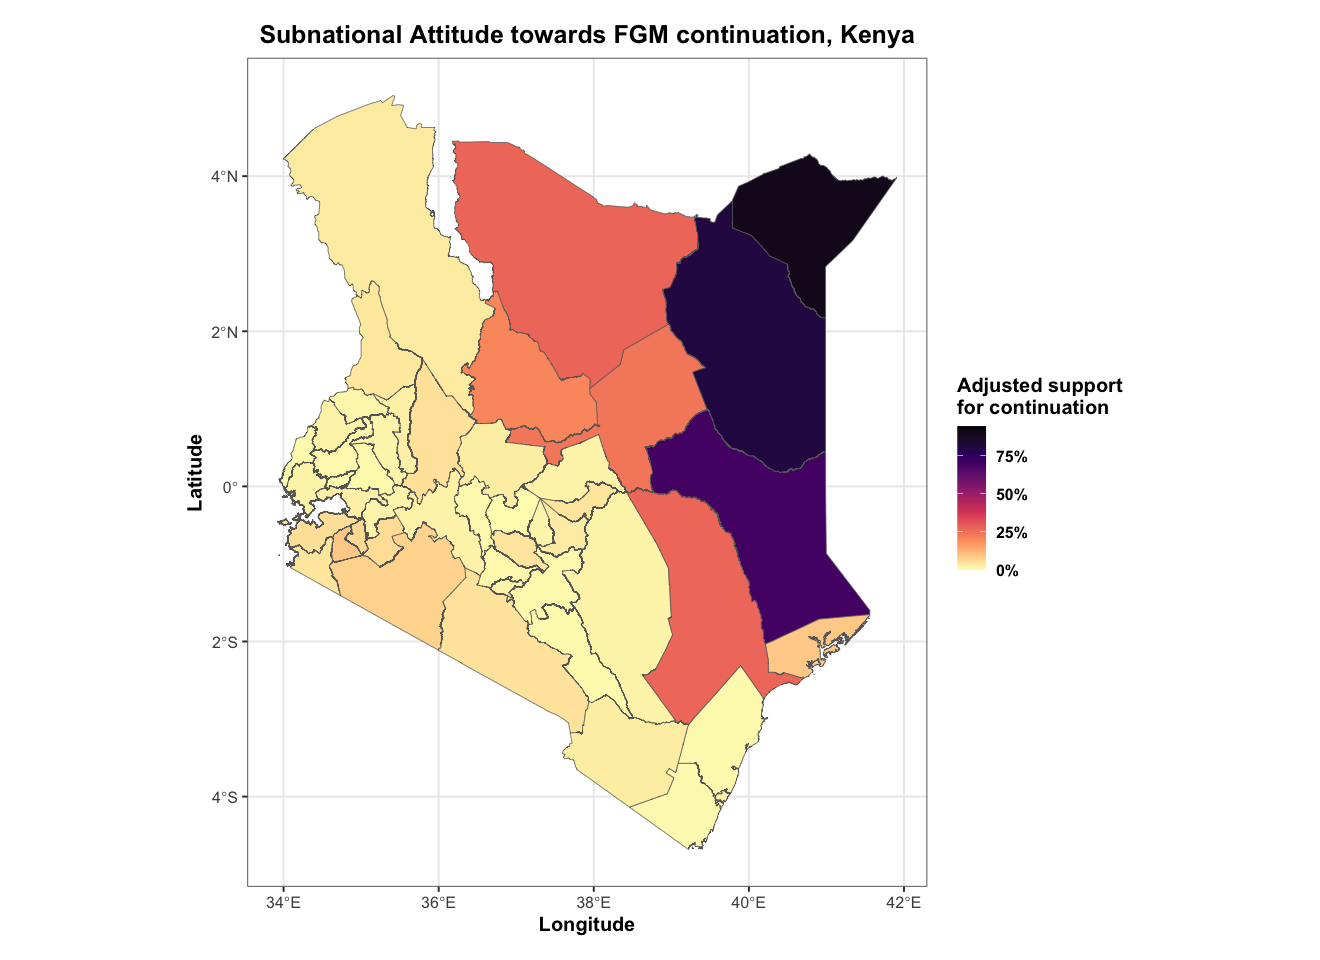

In [12]:
attitude_map_data <- boundaries |>
  dplyr::left_join(adjusted_state, by = c(".region_key" = "region"))

adjusted_attitude_map <- ggplot2::ggplot(attitude_map_data) +
  ggplot2::geom_sf(
    ggplot2::aes(fill = adjusted_support),
    color = "grey40", linewidth = 0.20
  ) +
  ggplot2::scale_fill_viridis_c(
    name = "Adjusted support\nfor continuation",
    option = "magma", direction = -1,
    labels = scales::percent_format(accuracy = 1),
    limits = c(0, max(attitude_map_data$adjusted_upper, na.rm = TRUE)),
    oob = scales::squish, na.value = "grey90"
  ) +
  ggplot2::coord_sf(datum = sf::st_crs(4326)) +
  ggplot2::labs(
    title = paste("Subnational Attitude towards FGM continuation,", country_name),
    x = "Longitude", y = "Latitude"
  ) +
  ggplot2::theme_bw(base_size = 12) +
  ggplot2::theme(
    text = ggplot2::element_text(face = "bold"),
    plot.title = ggplot2::element_text(size = 15, hjust = 0.5),
    legend.title = ggplot2::element_text(face = "bold"),
    panel.border = ggplot2::element_rect(color = "grey40", fill = NA),
    plot.margin = ggplot2::margin(15, 15, 15, 15)
  )

print(adjusted_attitude_map)
ggplot2::ggsave(
  file.path(output_dir, paste0(country_iso3, "_attitude_covariate_adjusted_map_v3.png")),
  adjusted_attitude_map, width = 9, height = 8, dpi = 300, bg = "white"
)

## 12. Residual geographic pattern

The BYM2 effect shows geographic variation remaining after adjustment for the
selected composition variables. It is a relative log-odds effect, not an
attitude-prevalence estimate.

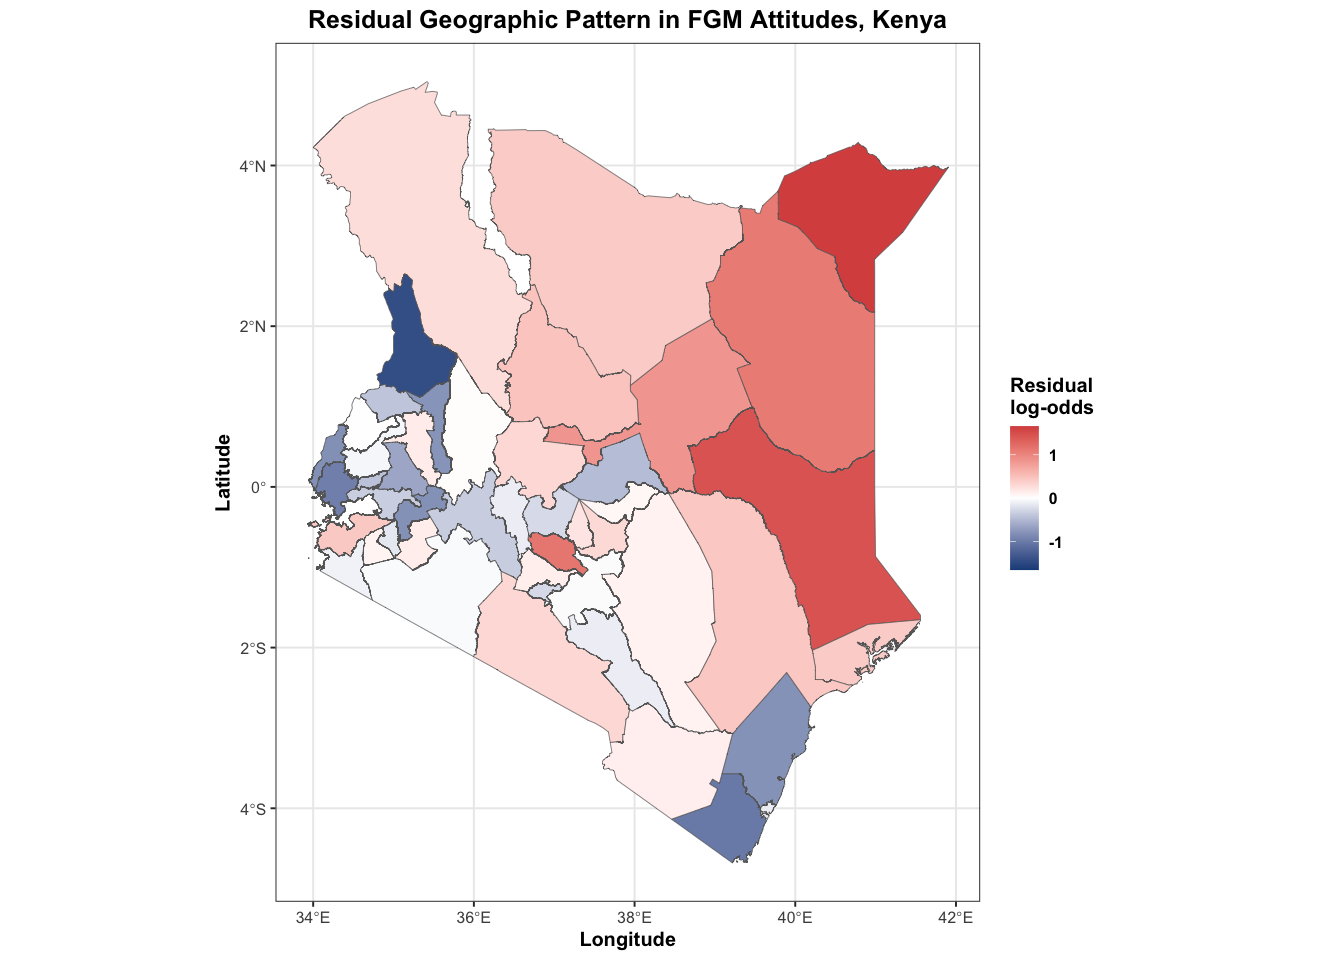

In [13]:
region_lookup <- model_data |>
  dplyr::distinct(region, region_id) |>
  dplyr::arrange(region_id)

residual_state <- adjusted_attitude_model$summary.random$region_id |>
  dplyr::filter(ID %in% region_lookup$region_id) |>
  dplyr::transmute(
    region_id = ID,
    residual_effect = mean,
    residual_lower = `0.025quant`,
    residual_upper = `0.975quant`
  ) |>
  dplyr::left_join(region_lookup, by = "region_id")

residual_map_data <- boundaries |>
  dplyr::left_join(residual_state, by = c(".region_key" = "region"))

residual_limit <- max(abs(residual_map_data$residual_effect), na.rm = TRUE)
residual_map <- ggplot2::ggplot(residual_map_data) +
  ggplot2::geom_sf(
    ggplot2::aes(fill = residual_effect), color = "grey40", linewidth = 0.20
  ) +
  ggplot2::scale_fill_gradient2(
    name = "Residual\nlog-odds",
    low = "#1D4E89", mid = "white", high = "#D9534F",
    midpoint = 0, limits = c(-residual_limit, residual_limit)
  ) +
  ggplot2::labs(
    title = paste("Residual Geographic Pattern in FGM Attitudes,", country_name),
    x = "Longitude", y = "Latitude"
  ) +
  ggplot2::theme_bw(base_size = 12) +
  ggplot2::theme(
    text = ggplot2::element_text(face = "bold"),
    plot.title = ggplot2::element_text(size = 15, hjust = 0.5)
  )

print(residual_map)
readr::write_csv(
  residual_state,
  file.path(output_dir, paste0(country_iso3, "_attitude_residual_spatial_effect_v3.csv"))
)
ggplot2::ggsave(
  file.path(output_dir, paste0(country_iso3, "_attitude_residual_map_v3.png")),
  residual_map, width = 9, height = 8, dpi = 300, bg = "white"
)

## 13. Validation and comparison

# A tibble: 1 × 5
  states_compared correlation_direct_adjusted mean_absolute_difference
            <int>                       <dbl>                    <dbl>
1              47                       0.999                  0.00566
# ℹ 2 more variables: root_mean_squared_difference <dbl>,
#   maximum_absolute_difference <dbl>


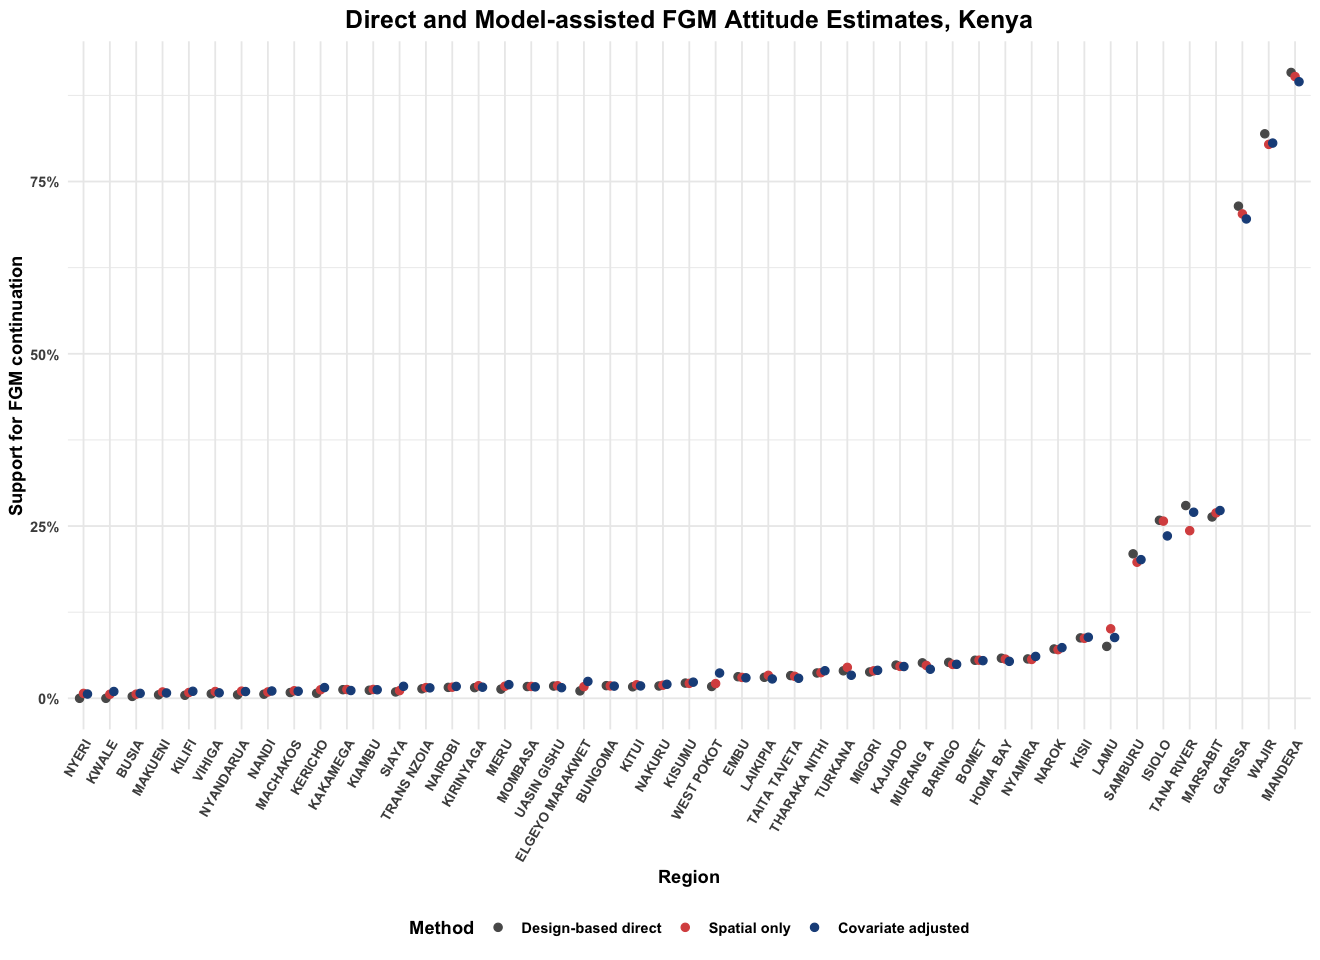

In [14]:
validation_metrics <- adjusted_state |>
  dplyr::summarise(
    states_compared = sum(stats::complete.cases(direct_support, adjusted_support)),
    correlation_direct_adjusted = stats::cor(
      direct_support, adjusted_support, use = "complete.obs"
    ),
    mean_absolute_difference = mean(
      abs(adjusted_support - direct_support), na.rm = TRUE
    ),
    root_mean_squared_difference = sqrt(mean(
      (adjusted_support - direct_support)^2, na.rm = TRUE
    )),
    maximum_absolute_difference = max(
      abs(adjusted_support - direct_support), na.rm = TRUE
    )
  )

validation_long <- adjusted_state |>
  dplyr::select(region, direct_support, spatial_only, adjusted_support) |>
  tidyr::pivot_longer(
    -region, names_to = "method", values_to = "support"
  ) |>
  dplyr::mutate(
    method = factor(
      method,
      levels = c("direct_support", "spatial_only", "adjusted_support"),
      labels = c("Design-based direct", "Spatial only", "Covariate adjusted")
    )
  )

validation_plot <- ggplot2::ggplot(
  validation_long,
  ggplot2::aes(x = reorder(region, support), y = support, color = method, group = method)
) +
  ggplot2::geom_point(position = ggplot2::position_dodge(width = 0.45), size = 2) +
  ggplot2::scale_y_continuous(labels = scales::percent_format(accuracy = 1)) +
  ggplot2::scale_color_manual(
    values = c(
      "Design-based direct" = "grey35",
      "Spatial only" = "#D9534F",
      "Covariate adjusted" = "#1D4E89"
    )
  ) +
  ggplot2::labs(
    title = paste("Direct and Model-assisted FGM Attitude Estimates,", country_name),
    x = "Region", y = "Support for FGM continuation", color = "Method"
  ) +
  ggplot2::theme_minimal(base_size = 11) +
  ggplot2::theme(
    text = ggplot2::element_text(face = "bold"),
    plot.title = ggplot2::element_text(hjust = 0.5, size = 15),
    axis.text.x = ggplot2::element_text(angle = 60, hjust = 1, size = 8),
    legend.position = "bottom"
  )

print(validation_metrics)
print(validation_plot)

readr::write_csv(
  validation_metrics,
  file.path(output_dir, paste0(country_iso3, "_attitude_validation_metrics_v3.csv"))
)
readr::write_csv(
  validation_long,
  file.path(output_dir, paste0(country_iso3, "_attitude_validation_comparison_v3.csv"))
)
ggplot2::ggsave(
  file.path(output_dir, paste0(country_iso3, "_attitude_validation_v3.png")),
  validation_plot, width = 12, height = 7, dpi = 300, bg = "white"
)

## 14. Interpretation and limitations

- The design-based national and regional estimates are the survey-design benchmark.
- The adjusted model uses normalized DHS weights in a pseudo-likelihood and
  again during posterior aggregation. Its intervals are pseudo-posterior, not
  fully design-based confidence intervals.
- Estimates apply to interviewed women with a known response to the attitude
  question; they should not be described as the views of daughters.
- Random-forest importance is descriptive and can favor variables with many
  categories. It ranks predictors but does not establish causality.
- Own FGM status and age are retained a priori. Region is represented once, by
  the BYM2 effect, rather than duplicated as a fixed effect.
- The previous cluster mean of the outcome is not used as a predictor, removing
  the outcome leakage present in v2.
- Predictions are averaged over the observed survey-weighted regional composition.
- County estimates with small effective samples or wide uncertainty intervals
  require additional caution.
  Full MRP would require external population counts for joint demographic cells.

In [15]:
cat("FGM Attitudinal Incidence v3 completed.\n")
cat("Selected predictors:", paste(selected_predictors, collapse = ", "), "\n")
cat("Direct national estimate:",
    scales::percent(direct_national$estimate, accuracy = 0.01), "\n")
cat("Adjusted national estimate:",
    scales::percent(adjusted_national$estimate, accuracy = 0.01), "\n")
cat("All outputs saved to:", normalizePath(output_dir, mustWork = FALSE), "\n")

FGM Attitudinal Incidence v3 completed.


Selected predictors: own_status, age, region, ethnicity, education, wealth, religion, urban_rural 


Direct national estimate: 4.38% 


Adjusted national estimate: 4.50% 


All outputs saved to: /Users/jkakai/Desktop/Main/Melaningod/UNFPA/Root/Working Folder/FGM_Risk_Attitude_Prevelance/03_Outputs/KEN/Attitude_v3 
